<a href="https://colab.research.google.com/github/MohamedIbrahim0101/Aqarat_AlRashed/blob/main/Vertufit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")


PyTorch: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4
GPU memory: 14.56 GB


In [2]:
%cd /content

!git clone https://github.com/fashn-AI/fashn-vton-1.5.git

%cd /content/fashn-vton-1.5

/content
Cloning into 'fashn-vton-1.5'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 92 (delta 20), reused 13 (delta 13), pack-reused 67 (from 1)
Receiving objects: 100% (92/92), 334.44 KiB | 37.16 MiB/s, done.
Resolving deltas: 100% (29/29), done.
/content/fashn-vton-1.5


In [3]:
%cd /content/fashn-vton-1.5

!pip install -e .


/content/fashn-vton-1.5
Obtaining file:///content/fashn-vton-1.5
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 5.1 MB/s eta 0:00:00
  Building editable for fashn-vton (pyproject.toml) ... done
  Created wheel for fashn-vton: filename=fashn_vton-1.5.0-0.editable-py3-none-any.whl size=5771 sha256=0763dd079cdc4f2a5326550d13657fd498ec10536032e5389c864b1400d8d774
  Stored in directory: /tmp/pip-ephem-wheel-cache-f41_6dmy/wheels/81/c7/ee/834de7859c1823447a7c5e12688cc45e439f96b49e9fa887ca
Successfully built fashn-vton


In [4]:
%cd /content/fashn-vton-1.5

!python scripts/download_weights.py --weights-dir ./weights

/content/fashn-vton-1.5



model.safetensors: downloading bytes:   0% 0.00/1.94G [00:00<?, ?B/s]
model.safetensors: downloading bytes:   0% 7.57M/1.94G [00:01<07:48, 4.13MB/s]
model.safetensors: downloading bytes:   1% 20.9M/1.94G [00:01<02:23, 13.4MB/s,  721kB/s  ]
model.safetensors: downloading bytes:   2% 31.9M/1.94G [00:02<01:25, 22.5MB/s, 1.98MB/s  ]
model.safetensors: downloading bytes:   2% 42.5M/1.94G [00:02<01:05, 29.0MB/s, 3.23MB/s  ]
model.safetensors: reconstructing file:   2% 39.1M/1.94G [00:02<01:00, 31.6MB/s, 2.86MB/s  ]
model.safetensors: downloading bytes:   3% 60.0M/1.94G [00:02<00:44, 42.5MB/s, 4.48MB/s  ]
model.safetensors: downloading bytes:   4% 69.4M/1.94G [00:02<00:37, 49.7MB/s, 5.51MB/s  ]
model.safetensors: reconstructing file:   4% 70.0M/1.94G [00:02<00:28, 65.9MB/s, 5.32MB/s  ]
model.safetensors: downloading bytes:   5% 90.6M/1.94G [00:02<00:28, 65.8MB/s, 6.91MB/s  ]
model.safetensors: downloading bytes:   6% 124M/1.94G [00:03<00:23, 76.1MB/s, 9.84MB/s  ]
mo

In [5]:
%cd /content/fashn-vton-1.5

!python examples/basic_inference.py \
    --weights-dir ./weights \
    --person-image examples/data/model.webp \
    --garment-image examples/data/garment.webp \
    --category tops \
    --num-timesteps 20 \
    --output-dir outputs

/content/fashn-vton-1.5
Loading images...
Loading pipeline from ./weights...
TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
2026-10-10 19:22:44.154367366 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-10 19:22:45.615547576 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-10 19:22:45.664890793 [W:onnxruntime:, session_state.cc:1598 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly as

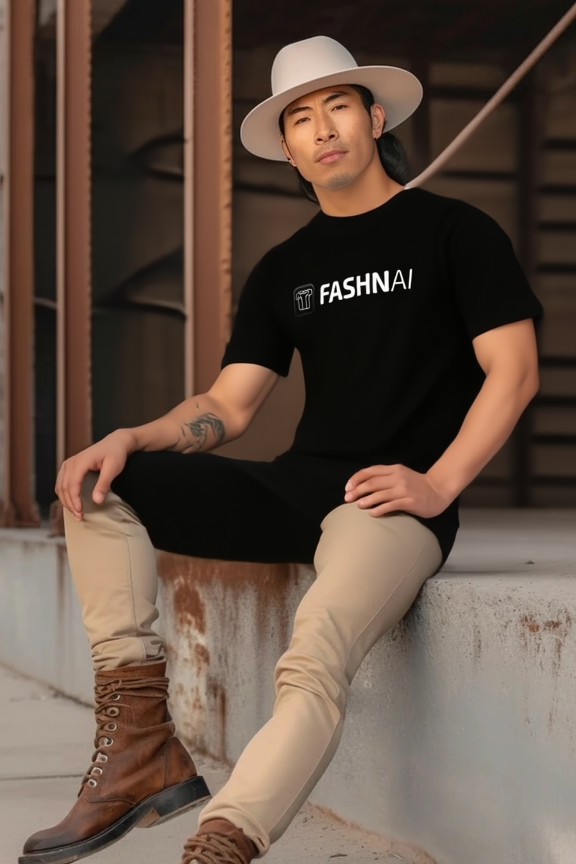

In [6]:
from PIL import Image
from IPython.display import display

result = Image.open(
    "/content/fashn-vton-1.5/outputs/output_00.png"
)

display(result)

In [7]:
from google.colab import files

uploaded = files.upload()

Saving WhatsApp Image 2026-09-21 at 7.25.30 PM.jpeg to WhatsApp Image 2026-09-21 at 7.25.30 PM.jpeg


In [8]:
import os

person_image = "/content/fashn-vton-1.5/WhatsApp Image 2026-09-21 at 7.25.30 PM.jpeg"
garment_image = "/content/fashn-vton-1.5/spider_man.jpg"

print("Person image exists:", os.path.exists(person_image))
print("T-shirt image exists:", os.path.exists(garment_image))

Person image exists: True
T-shirt image exists: False


In [9]:
from google.colab import files

uploaded = files.upload()


Saving spider_man.jpg to spider_man.jpg


In [10]:
import os

person_image = "/content/fashn-vton-1.5/WhatsApp Image 2026-09-21 at 7.25.30 PM.jpeg"
garment_image = "/content/fashn-vton-1.5/spider_man.jpg"

print("Person image exists:", os.path.exists(person_image))
print("T-shirt image exists:", os.path.exists(garment_image))

Person image exists: True
T-shirt image exists: True


In [12]:
%cd /content/fashn-vton-1.5

!python examples/basic_inference.py \
  --weights-dir ./weights \
  --person-image "/content/fashn-vton-1.5/WhatsApp Image 2026-09-21 at 7.25.30 PM.jpeg" \
  --garment-image "/content/fashn-vton-1.5/spider_man.jpg" \
  --category tops \
  --num-timesteps 20 \
  --output-dir outputs

/content/fashn-vton-1.5
Loading images...
Loading pipeline from ./weights...
TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
2026-10-10 19:37:22.097814886 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-10 19:37:23.168232380 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-10 19:37:23.213203851 [W:onnxruntime:, session_state.cc:1598 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly as

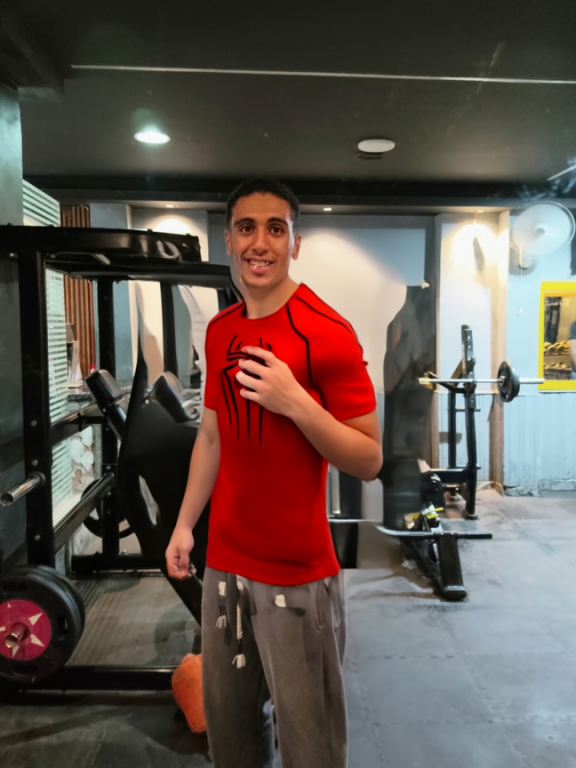

In [13]:
from IPython.display import display, Image
import glob
import os

images = glob.glob("outputs/output_*.png")

if images:
    latest_image = max(images, key=os.path.getmtime)
    display(Image(filename=latest_image))
else:
    print("ملقتش صورة ناتجة. ابعتلي رسالة الخطأ.")

In [17]:
from google.colab import files

uploaded = files.upload()

print("الصور المرفوعة:")
for name in uploaded.keys():
    print(name)


Saving man.jpg to man (1).jpg
الصور المرفوعة:
man (1).jpg


In [19]:
from google.colab import files

uploaded = files.upload()

Saving man.jpg to man (2).jpg


In [20]:
import os

person_image = os.path.abspath("man.jpg")

print("Path:", person_image)
print("Exists:", os.path.exists(person_image))

Path: /content/fashn-vton-1.5/man.jpg
Exists: True


In [23]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/man.jpg"
garment_image = "/content/fashn-vton-1.5/spider_man.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/test_man"

os.makedirs(output_dir, exist_ok=True)

result = subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "tops",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], capture_output=True, text=True)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

/content/fashn-vton-1.5
Loading images...
Loading pipeline from ./weights...
Saved: /content/fashn-vton-1.5/outputs/test_man/output_00.png

Done! Generated 1 images.



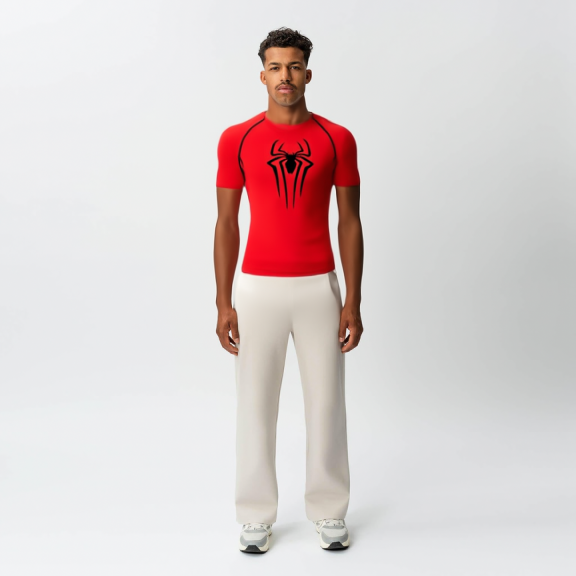

In [24]:
from IPython.display import display, Image
import glob
import os

images = glob.glob(output_dir + "/output_*.png")

if images:
    latest_image = max(images, key=os.path.getmtime)
    display(Image(filename=latest_image))
else:
    print("لم يتم العثور على صورة ناتجة.")

In [25]:
from google.colab import files

uploaded = files.upload()

Saving pants.jpg to pants.jpg


In [26]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/man.jpg"
pants_image = "/content/fashn-vton-1.5/pants.jpg"

output_dir = "/content/fashn-vton-1.5/outputs/test_pants"
os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة الشخص غير موجودة"
assert os.path.exists(pants_image), "صورة البنطلون غير موجودة"

result = subprocess.run(
    [
        "python", "examples/basic_inference.py",
        "--weights-dir", "./weights",
        "--person-image", person_image,
        "--garment-image", pants_image,
        "--category", "bottoms",
        "--num-timesteps", "20",
        "--output-dir", output_dir
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

/content/fashn-vton-1.5
Loading images...
Loading pipeline from ./weights...
Saved: /content/fashn-vton-1.5/outputs/test_pants/output_00.png

Done! Generated 1 images.



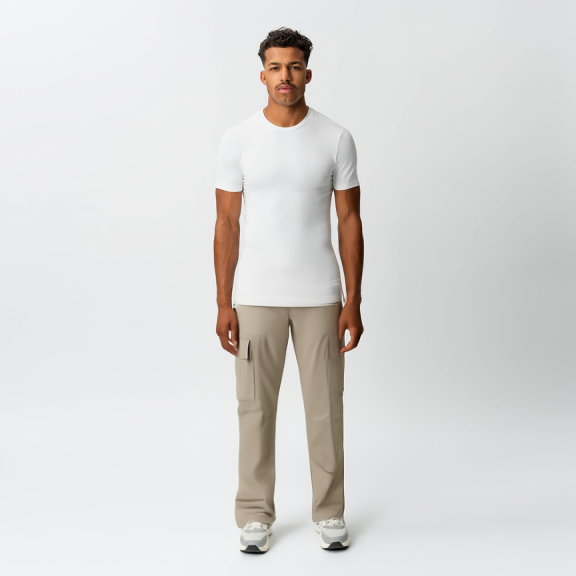

In [27]:
from IPython.display import display, Image
import glob
import os

images = glob.glob(output_dir + "/output_*.png")

if images:
    latest_image = max(images, key=os.path.getmtime)
    display(Image(filename=latest_image))
else:
    print("لم يتم العثور على صورة ناتجة.")

In [28]:
from google.colab import files

uploaded = files.upload()

Saving side.jpg to side.jpg


In [29]:
from google.colab import files

uploaded = files.upload()


Saving test_c.jpg to test_c.jpg


In [30]:
from google.colab import files

uploaded = files.upload()

Saving test_d.jpg to test_d.jpg


In [31]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/side.jpg"
garment_image = "/content/fashn-vton-1.5/pants.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/pose_side"

os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة side.jpg غير موجودة"
assert os.path.exists(garment_image), "صورة pants.jpg غير موجودة"

subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "bottoms",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], check=True)

/content/fashn-vton-1.5


CompletedProcess(args=['python', 'examples/basic_inference.py', '--weights-dir', './weights', '--person-image', '/content/fashn-vton-1.5/side.jpg', '--garment-image', '/content/fashn-vton-1.5/pants.jpg', '--category', 'bottoms', '--num-timesteps', '20', '--output-dir', '/content/fashn-vton-1.5/outputs/pose_side'], returncode=0)

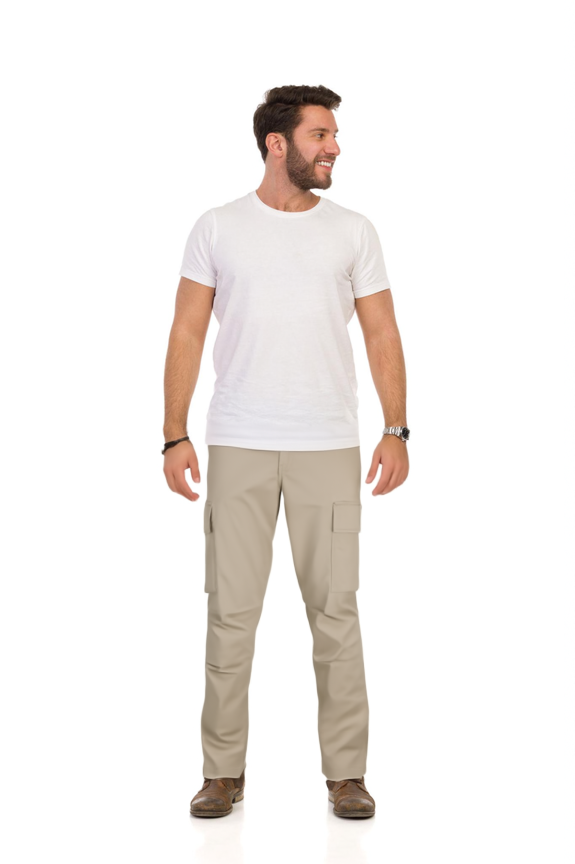

In [32]:
from IPython.display import display, Image
import glob
import os

output_dir = "/content/fashn-vton-1.5/outputs/pose_side"
images = glob.glob(os.path.join(output_dir, "output_*.png"))

if images:
    latest = max(images, key=os.path.getmtime)
    display(Image(filename=latest))
else:
    print("لم يتم العثور على صورة ناتجة.")

In [33]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/test_c.jpg"
garment_image = "/content/fashn-vton-1.5/pants.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/pose_test_c"

os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة test_c.jpg غير موجودة"
assert os.path.exists(garment_image), "صورة pants.jpg غير موجودة"

subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "bottoms",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], check=True)

/content/fashn-vton-1.5


CompletedProcess(args=['python', 'examples/basic_inference.py', '--weights-dir', './weights', '--person-image', '/content/fashn-vton-1.5/test_c.jpg', '--garment-image', '/content/fashn-vton-1.5/pants.jpg', '--category', 'bottoms', '--num-timesteps', '20', '--output-dir', '/content/fashn-vton-1.5/outputs/pose_test_c'], returncode=0)

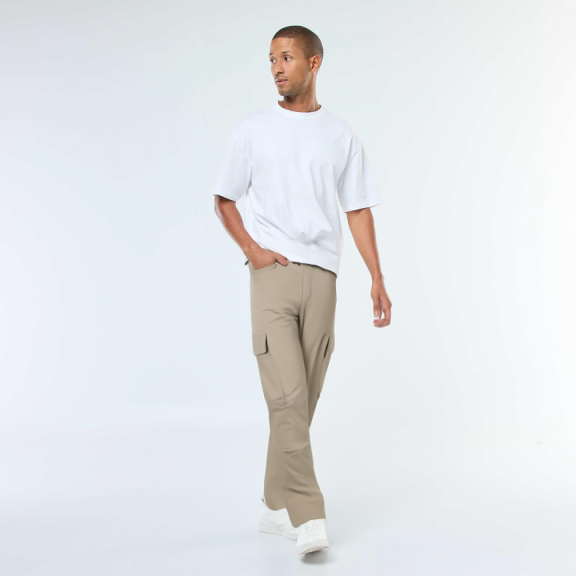

In [36]:
from IPython.display import display, Image
import glob
import os

output_dir = "/content/fashn-vton-1.5/outputs/pose_test_c"
images = glob.glob(os.path.join(output_dir, "output_*.png"))

if images:
    latest = max(images, key=os.path.getmtime)
    display(Image(filename=latest))
else:
    print("لم يتم العثور على صورة ناتجة.")

In [35]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/test_d.jpg"
garment_image = "/content/fashn-vton-1.5/pants.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/pose_test_d"

os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة test_d.jpg غير موجودة"
assert os.path.exists(garment_image), "صورة pants.jpg غير موجودة"

subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "bottoms",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], check=True)

/content/fashn-vton-1.5


CompletedProcess(args=['python', 'examples/basic_inference.py', '--weights-dir', './weights', '--person-image', '/content/fashn-vton-1.5/test_d.jpg', '--garment-image', '/content/fashn-vton-1.5/pants.jpg', '--category', 'bottoms', '--num-timesteps', '20', '--output-dir', '/content/fashn-vton-1.5/outputs/pose_test_d'], returncode=0)

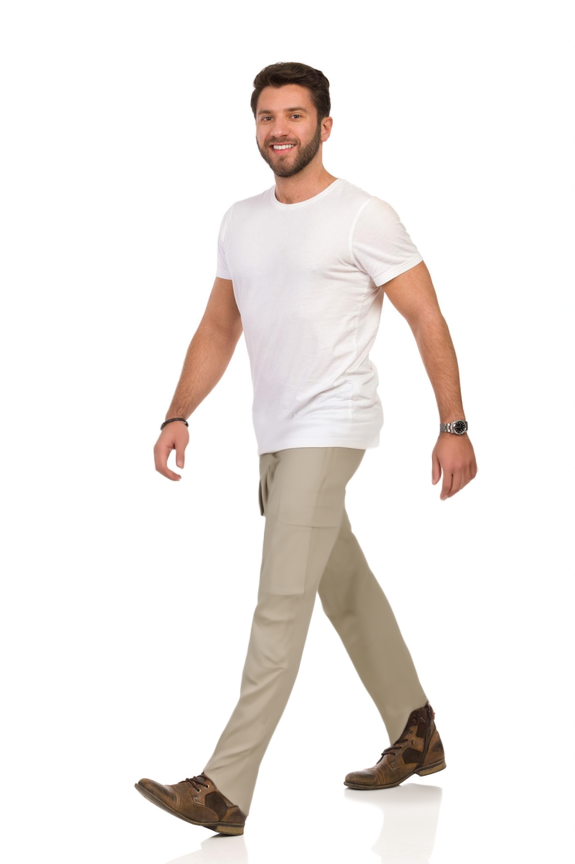

In [37]:
from IPython.display import display, Image
import glob
import os

output_dir = "/content/fashn-vton-1.5/outputs/pose_test_d"
images = glob.glob(os.path.join(output_dir, "output_*.png"))

if images:
    latest = max(images, key=os.path.getmtime)
    display(Image(filename=latest))
else:
    print("لم يتم العثور على صورة ناتجة.")

In [38]:
from google.colab import files

uploaded = files.upload()

Saving testa.jpg to testa.jpg


In [39]:
from google.colab import files

uploaded = files.upload()

Saving arms.jpg to arms.jpg


In [40]:
from google.colab import files

uploaded = files.upload()

Saving baggy_test.jpg to baggy_test.jpg


In [41]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/testa.jpg"
garment_image = "/content/fashn-vton-1.5/pants.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/hard_test_a"

os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة testa.jpg غير موجودة"
assert os.path.exists(garment_image), "صورة pants.jpg غير موجودة"

subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "bottoms",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], check=True)

/content/fashn-vton-1.5


CompletedProcess(args=['python', 'examples/basic_inference.py', '--weights-dir', './weights', '--person-image', '/content/fashn-vton-1.5/testa.jpg', '--garment-image', '/content/fashn-vton-1.5/pants.jpg', '--category', 'bottoms', '--num-timesteps', '20', '--output-dir', '/content/fashn-vton-1.5/outputs/hard_test_a'], returncode=0)

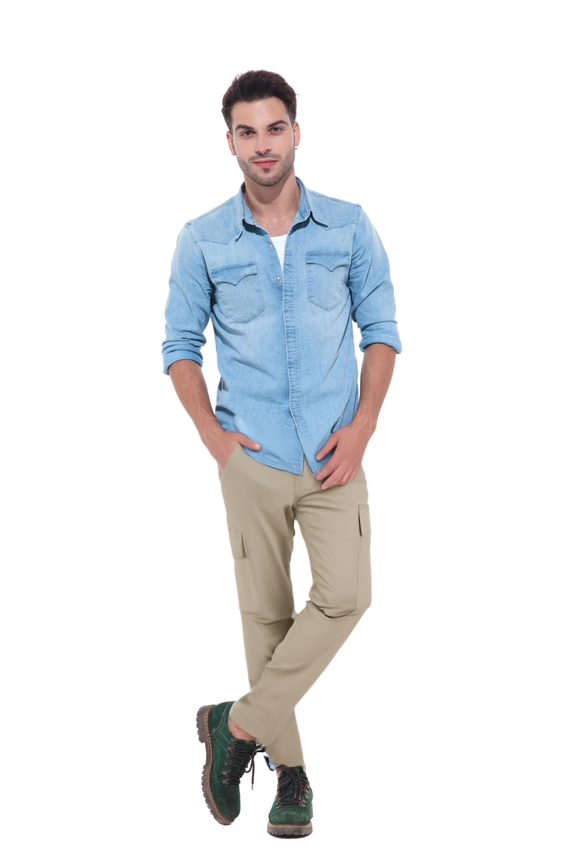

In [42]:
from IPython.display import display, Image
import glob
import os

output_dir = "//content/fashn-vton-1.5/outputs/hard_test_a"
images = glob.glob(os.path.join(output_dir, "output_*.png"))

if images:
    latest = max(images, key=os.path.getmtime)
    display(Image(filename=latest))
else:
    print("لم يتم العثور على صورة ناتجة.")

In [43]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/arms.jpg"
garment_image = "/content/fashn-vton-1.5/spider_man.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/hard_test_arms"

os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة arms.jpg غير موجودة"
assert os.path.exists(garment_image), "صورة pants.jpg غير موجودة"

subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "bottoms",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], check=True)

/content/fashn-vton-1.5


CompletedProcess(args=['python', 'examples/basic_inference.py', '--weights-dir', './weights', '--person-image', '/content/fashn-vton-1.5/arms.jpg', '--garment-image', '/content/fashn-vton-1.5/spider_man.jpg', '--category', 'bottoms', '--num-timesteps', '20', '--output-dir', '/content/fashn-vton-1.5/outputs/hard_test_arms'], returncode=0)

In [ ]:
%cd /content/fashn-vton-1.5

import os
import subprocess

person_image = "/content/fashn-vton-1.5/baggy_test.jpg"
garment_image = "/content/fashn-vton-1.5/pants.jpg"
output_dir = "/content/fashn-vton-1.5/outputs/hard_test_baggy"

os.makedirs(output_dir, exist_ok=True)

assert os.path.exists(person_image), "صورة baggy_test.jpg غير موجودة"
assert os.path.exists(garment_image), "صورة pants.jpg غير موجودة"

subprocess.run([
    "python", "examples/basic_inference.py",
    "--weights-dir", "./weights",
    "--person-image", person_image,
    "--garment-image", garment_image,
    "--category", "bottoms",
    "--num-timesteps", "20",
    "--output-dir", output_dir
], check=True)

In [44]:

from pathlib import Path
import csv

# مسار مشروع FASHN الموجود في Google Colab
PROJECT_DIR = Path("/content/fashn-vton-1.5")

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "مجلد الموديل غير موجود. تأكد أنك فتحت الـ Colab "
        "الذي جهزنا عليه FASHN VTON."
    )

# مجلدات بيانات التقييم
DATA_DIR = PROJECT_DIR / "datasets" / "virtufit_eval"

folders = [
    DATA_DIR / "people",
    DATA_DIR / "garments",
    DATA_DIR / "outputs",
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# ملف تسجيل حالات الاختبار ونتائجها
metadata_file = DATA_DIR / "metadata.csv"

columns = [
    "case_id",
    "person_image",
    "garment_image",
    "category",
    "pose_type",
    "garment_type",
    "output_image",
    "inference_seconds",
    "visual_score",
    "notes",
]

if not metadata_file.exists():
    with open(metadata_file, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()

print("Dataset evaluation structure is ready!")
print(f"Project: {PROJECT_DIR}")
print(f"Dataset: {DATA_DIR}")
print("\nFolders:")
for folder in folders:
    print(f"- {folder}")

print(f"\nMetadata file: {metadata_file}")

Dataset evaluation structure is ready!
Project: /content/fashn-vton-1.5
Dataset: /content/fashn-vton-1.5/datasets/virtufit_eval

Folders:
- /content/fashn-vton-1.5/datasets/virtufit_eval/people
- /content/fashn-vton-1.5/datasets/virtufit_eval/garments
- /content/fashn-vton-1.5/datasets/virtufit_eval/outputs

Metadata file: /content/fashn-vton-1.5/datasets/virtufit_eval/metadata.csv


In [45]:

!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   46G   68G  41% /


In [46]:

!pip -q install gdown

!gdown --fuzzy "https://drive.google.com/file/d/1tLx8LRp-sxDp0EcYmYoV_vXdSc-jJ79w/view" \
    -O /content/VITON-HD.zip

Downloading...
From (original): https://drive.google.com/uc?id=1tLx8LRp-sxDp0EcYmYoV_vXdSc-jJ79w
From (redirected): https://drive.google.com/uc?id=1tLx8LRp-sxDp0EcYmYoV_vXdSc-jJ79w&confirm=t&uuid=3749261f-fc9d-466d-a1b5-9a73ba998ff4
To: /content/VITON-HD.zip
100% 4.87G/4.87G [01:24<00:00, 57.8MB/s]


In [47]:

import os

path = "/content/VITON-HD.zip"

if os.path.exists(path):
    size_gb = os.path.getsize(path) / (1024 ** 3)
    print(f"Download complete: {size_gb:.2f} GB")
else:
    print("Dataset file not found.")

Download complete: 4.53 GB


In [48]:

import zipfile
import shutil
import os

zip_path = "/content/VITON-HD.zip"

print("Archive valid:", zipfile.is_zipfile(zip_path))
print("Free Colab space:", round(
    shutil.disk_usage("/content").free / (1024**3), 2
), "GB")

with zipfile.ZipFile(zip_path, "r") as z:
    print("\nFirst 25 files:")
    for name in z.namelist()[:25]:
        print(name)

    print("\nTotal files:", len(z.namelist()))
    print("Uncompressed size:", round(
        sum(info.file_size for info in z.infolist()) / (1024**3), 2
    ), "GB")

Archive valid: True
Free Colab space: 62.76 GB

First 25 files:
test/
test/agnostic-mask/
test/agnostic-mask/00006_00_mask.png
test/agnostic-mask/00008_00_mask.png
test/agnostic-mask/00013_00_mask.png
test/agnostic-mask/00017_00_mask.png
test/agnostic-mask/00034_00_mask.png
test/agnostic-mask/00035_00_mask.png
test/agnostic-mask/00055_00_mask.png
test/agnostic-mask/00057_00_mask.png
test/agnostic-mask/00064_00_mask.png
test/agnostic-mask/00067_00_mask.png
test/agnostic-mask/00069_00_mask.png
test/agnostic-mask/00071_00_mask.png
test/agnostic-mask/00074_00_mask.png
test/agnostic-mask/00075_00_mask.png
test/agnostic-mask/00084_00_mask.png
test/agnostic-mask/00094_00_mask.png
test/agnostic-mask/00095_00_mask.png
test/agnostic-mask/00096_00_mask.png
test/agnostic-mask/00110_00_mask.png
test/agnostic-mask/00112_00_mask.png
test/agnostic-mask/00121_00_mask.png
test/agnostic-mask/00126_00_mask.png
test/agnostic-mask/00127_00_mask.png

Total files: 148462
Uncompressed size: 5.18 GB


In [49]:

import zipfile
from collections import Counter

zip_path = "/content/VITON-HD.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    counts = Counter()

    for name in z.namelist():
        if name.endswith("/"):
            continue

        parts = name.split("/")
        if len(parts) >= 2:
            counts["/".join(parts[:2])] += 1

    for folder, count in sorted(counts.items()):
        print(f"{folder}: {count} files")

test/agnostic-mask: 2032 files
test/agnostic-v3.2: 2032 files
test/cloth: 2032 files
test/cloth-mask: 2032 files
test/image: 2032 files
test/image-densepose: 2032 files
test/image-parse-agnostic-v3.2: 2032 files
test/image-parse-v3: 2032 files
test/openpose_img: 2032 files
test/openpose_json: 2032 files
train/agnostic-mask: 11647 files
train/agnostic-v3.2: 11647 files
train/cloth: 11647 files
train/cloth-mask: 11647 files
train/gt_cloth_warped_mask: 11647 files
train/image: 11647 files
train/image-densepose: 11647 files
train/image-parse-agnostic-v3.2: 11647 files
train/image-parse-v3: 11647 files
train/openpose_img: 11647 files
train/openpose_json: 11647 files


In [50]:

import zipfile
import os
import random
import shutil

ZIP_PATH = "/content/VITON-HD.zip"
BASE_DIR = "/content/virtufit_dataset"
PERSON_DIR = os.path.join(BASE_DIR, "persons")
GARMENT_DIR = os.path.join(BASE_DIR, "garments")

os.makedirs(PERSON_DIR, exist_ok=True)
os.makedirs(GARMENT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    names = set(z.namelist())

    person_files = sorted(
        name for name in names
        if name.startswith("test/image/")
        and not name.endswith("/")
    )

    selected = person_files[:50]

    copied = 0
    for person_path in selected:
        filename = os.path.basename(person_path)

        # مثال: 00006_00.jpg -> 00006_00.jpg
        garment_path = "test/cloth/" + filename

        if garment_path not in names:
            print("Missing garment pair:", filename)
            continue

        with z.open(person_path) as src:
            with open(os.path.join(PERSON_DIR, filename), "wb") as dst:
                shutil.copyfileobj(src, dst)

        with z.open(garment_path) as src:
            with open(os.path.join(GARMENT_DIR, filename), "wb") as dst:
                shutil.copyfileobj(src, dst)

        copied += 1

print("Person images extracted:", len(os.listdir(PERSON_DIR)))
print("Garment images extracted:", len(os.listdir(GARMENT_DIR)))
print("Complete pairs:", copied)

Person images extracted: 50
Garment images extracted: 50
Complete pairs: 50


Persons: 50
Garments: 50


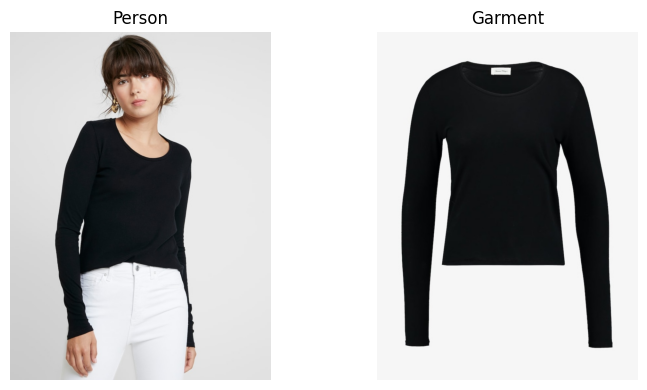

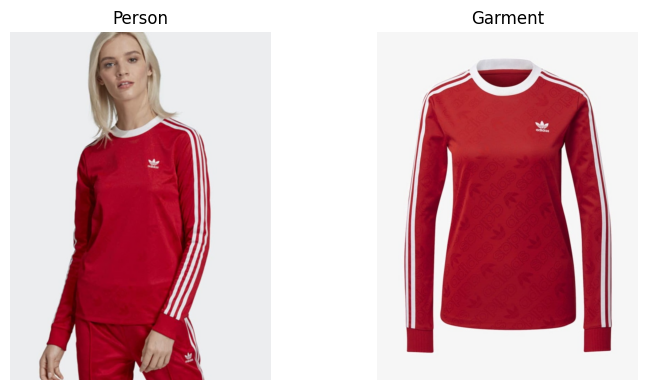

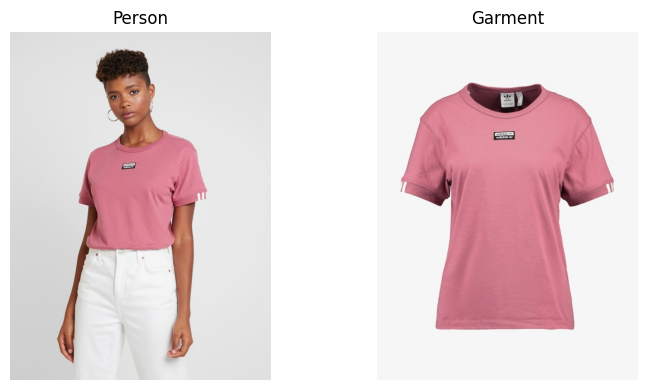

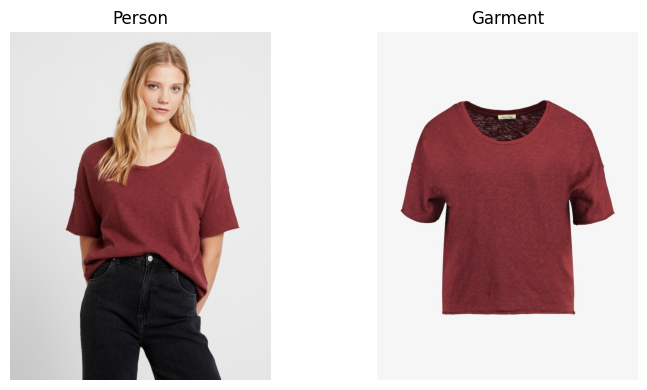

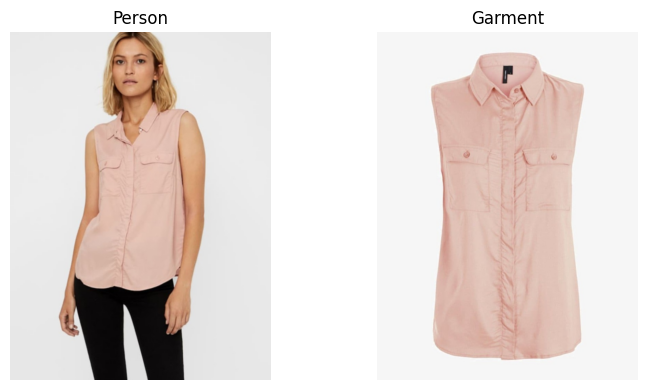

In [51]:
import os
import matplotlib.pyplot as plt
from PIL import Image

person_dir = "/content/virtufit_dataset/persons"
garment_dir = "/content/virtufit_dataset/garments"

person_files = sorted(os.listdir(person_dir))
garment_files = sorted(os.listdir(garment_dir))

print("Persons:", len(person_files))
print("Garments:", len(garment_files))

for person_name in person_files[:5]:
    garment_name = person_name  # نفس الاسم في المجلدين

    person_path = os.path.join(person_dir, person_name)
    garment_path = os.path.join(garment_dir, garment_name)

    if not os.path.exists(garment_path):
        print("Missing garment:", garment_name)
        continue

    person_img = Image.open(person_path).convert("RGB")
    garment_img = Image.open(garment_path).convert("RGB")

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(person_img)
    axes[0].set_title("Person")
    axes[0].axis("off")

    axes[1].imshow(garment_img)
    axes[1].set_title("Garment")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [52]:
import torch
import os

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

print("\nDataset directories:")

for path in [
    "/content/virtufit_dataset/persons",
    "/content/virtufit_dataset/garments",
]:
    print(path, "->", os.path.isdir(path))

GPU available: True
GPU name: Tesla T4
GPU memory: 14.56 GB

Dataset directories:
/content/virtufit_dataset/persons -> True
/content/virtufit_dataset/garments -> True


In [53]:
%cd /content

!git clone https://github.com/fashn-AI/fashn-vton-1.5.git
%cd /content/fashn-vton-1.5

!pip install -e .

/content
fatal: destination path 'fashn-vton-1.5' already exists and is not an empty directory.
/content/fashn-vton-1.5
Obtaining file:///content/fashn-vton-1.5
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fashn-vton (pyproject.toml) ... done
  Created wheel for fashn-vton: filename=fashn_vton-1.5.0-0.editable-py3-none-any.whl size=5771 sha256=0a56ad244bbba4675eeaad6512b243a35627895995ed56decd15975023972c74
  Stored in directory: /tmp/pip-ephem-wheel-cache-n9zttpu8/wheels/81/c7/ee/834de7859c1823447a7c5e12688cc45e439f96b49e9fa887ca
Successfully built fashn-vton
  Attempting uninstall: fashn-vton
    Found existing installation: fashn-vton 1.5.0
    Uninstalling fashn-vton-1.5.0:
      Successfully uninstalled fashn-vton-1.5.0


In [54]:
%cd /content/fashn-vton-1.5

!python scripts/download_weights.py --weights-dir ./weights

/content/fashn-vton-1.5


  Saved to: /content/fashn-vton-1.5/weights/model.safetensors

  Saved to: /content/fashn-vton-1.5/weights/dwpose/yolox_l.onnx
  Saved to: /content/fashn-vton-1.5/weights/dwpose/dw-ll_ucoco_384.onnx

Loading weights: 100% 930/930 [00:00<00:00, 1427.25it/s]
  Cached in HuggingFace hub cache

Download complete!

Weights directory structure:
    /content/fashn-vton-1.5/weights/
    ├── model.safetensors
    └── dwpose/
        ├── yolox_l.onnx
        └── dw-ll_ucoco_384.onnx

Usage:
    from fashn_vton import TryOnPipeline
    pipeline = TryOnPipeline(weights_dir="/content/fashn-vton-1.5/weights")



In [56]:
import os

repo = "/content/fashn-vton-1.5"

print("Repository exists:", os.path.isdir(repo))

if os.path.isdir(repo):
    for root, dirs, files in os.walk(repo):
        depth = root.replace(repo, "").count(os.sep)

        if depth > 2:
            dirs[:] = []
            continue

        print(root.replace(repo, "."))

        for filename in files:
            if filename.endswith(".py"):
                print("   ", filename)

Repository exists: True
.
./datasets
./datasets/virtufit_eval
./.git
./.git/info
./.git/logs
./.git/refs
./.git/hooks
./.git/branches
./.git/objects
./weights
./weights/dwpose
./weights/.cache
./outputs
./outputs/hard_test_arms
./outputs/test_man
./outputs/test_pants
./outputs/pose_side
./outputs/pose_test_d
./outputs/pose_test_c
./outputs/hard_test_a
./src
./src/fashn_vton.egg-info
./src/fashn_vton
    __init__.py
    pipeline.py
    tryon_mmdit.py
./scripts
    download_weights.py
    debug_masks.py
./tests
    test_pose_shapes.py
./examples
    basic_inference.py
./examples/data


In [57]:
import os
import sys

repo = "/content/fashn-vton-1.5"

# Add the source directory to Python's import path
src_path = os.path.join(repo, "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import the pipeline
import fashn_vton
from fashn_vton import TryOnPipeline

print("Import successful!")
print("Module location:", fashn_vton.__file__)
print("Pipeline class:", TryOnPipeline)

Import successful!
Module location: /content/fashn-vton-1.5/src/fashn_vton/__init__.py
Pipeline class: <class 'fashn_vton.pipeline.TryOnPipeline'>


TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors


Person: 00006_00.jpg
Garment: 00006_00.jpg


TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
TryOnPipeline - INFO - DWPose loaded
TryOnPipeline - INFO - Loading FashnHumanParser


Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

TryOnPipeline - INFO - FashnHumanParser loaded
TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


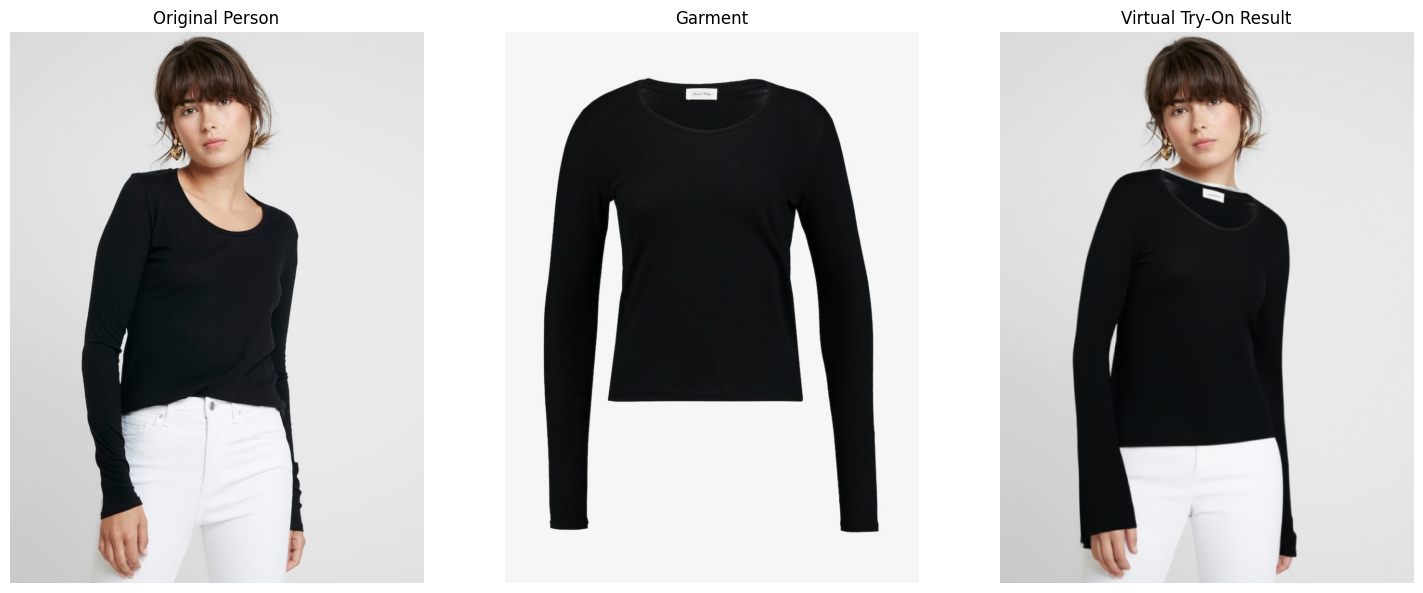

Result saved to: /content/virtufit_dataset/outputs/tryon_result.png


In [58]:
import os
from PIL import Image
import matplotlib.pyplot as plt
from fashn_vton import TryOnPipeline

person_dir = "/content/virtufit_dataset/persons"
garment_dir = "/content/virtufit_dataset/garments"

person_files = sorted(os.listdir(person_dir))
garment_files = sorted(os.listdir(garment_dir))

# اختيار أول زوج مكتمل
person_name = person_files[0]
garment_name = person_name

person_path = os.path.join(person_dir, person_name)
garment_path = os.path.join(garment_dir, garment_name)

assert os.path.isfile(garment_path), "Garment image not found!"

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGB")

print("Person:", person_name)
print("Garment:", garment_name)

# تحميل الموديل
pipeline = TryOnPipeline(
    weights_dir="/content/fashn-vton-1.5/weights",
    device="cuda"
)

# نوع القطعة: tops أو bottoms أو one-pieces
result = pipeline(
    person_image=person,
    garment_image=garment,
    category="tops"
)

# حفظ النتيجة
os.makedirs("/content/virtufit_dataset/outputs", exist_ok=True)

output_path = "/content/virtufit_dataset/outputs/tryon_result.png"
result.images[0].save(output_path)

# عرض الصور الثلاث للمقارنة
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(person)
axes[0].set_title("Original Person")

axes[1].imshow(garment)
axes[1].set_title("Garment")

axes[2].imshow(result.images[0])
axes[2].set_title("Virtual Try-On Result")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Result saved to:", output_path)

In [59]:
repo = "/content/fashn-vton-1.5"

with open(
    f"{repo}/examples/basic_inference.py",
    "r",
    encoding="utf-8"
) as f:
    print(f.read())

#!/usr/bin/env python3
"""Basic inference example."""

import argparse
import sys
from pathlib import Path

from PIL import Image

from fashn_vton import TryOnPipeline


def main():
    parser = argparse.ArgumentParser(
        description="FASHN VTON v1.5",
        formatter_class=argparse.RawDescriptionHelpFormatter,
        epilog="""
Example:
    python examples/basic_inference.py \\
        --weights-dir ./weights \\
        --person-image examples/data/model.webp \\
        --garment-image examples/data/garment.webp \\
        --category tops
        """,
    )
    parser.add_argument("--weights-dir", type=str, required=True, help="Directory containing model weights")
    parser.add_argument("--person-image", type=str, required=True, help="Path to person image")
    parser.add_argument("--garment-image", type=str, required=True, help="Path to garment image")
    parser.add_argument(
        "--category",
        type=str,
        choices=["tops", "bottoms", "one-pieces"],
       

In [60]:
import os
import sys
import torch
from PIL import Image
import matplotlib.pyplot as plt

# Project paths
repo = "/content/fashn-vton-1.5"
person_dir = "/content/virtufit_dataset/persons"
garment_dir = "/content/virtufit_dataset/garments"
weights_dir = f"{repo}/weights"
output_dir = f"{repo}/outputs/virtufit_first_test"

# Make the package importable
sys.path.insert(0, f"{repo}/src")

from fashn_vton import TryOnPipeline

# Verify environment
assert torch.cuda.is_available(), "GPU is not enabled!"
assert os.path.isdir(person_dir), f"Person directory not found: {person_dir}"
assert os.path.isdir(garment_dir), f"Garment directory not found: {garment_dir}"
assert os.path.isdir(weights_dir), "Weights directory not found!"

print("GPU:", torch.cuda.get_device_name(0))
print("Model package:", repo)
print("Ready to test!")

GPU: Tesla T4
Model package: /content/fashn-vton-1.5
Ready to test!


In [1]:
import torch
import psutil

print("RAM used:", round(psutil.virtual_memory().used / 1024**3, 2), "GB")
print("RAM available:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")
print("GPU:", torch.cuda.get_device_name(0))
print("GPU allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("GPU reserved:", round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

RAM used: 1.27 GB
RAM available: 11.09 GB
GPU: Tesla T4
GPU allocated: 0.0 GB
GPU reserved: 0.0 GB


In [2]:
import sys
import gc
import torch

repo = "/content/fashn-vton-1.5"
sys.path.insert(0, f"{repo}/src")

from fashn_vton import TryOnPipeline

gc.collect()
torch.cuda.empty_cache()

pipeline = TryOnPipeline(
    weights_dir=f"{repo}/weights",
    device="cuda"
)

print("Pipeline loaded successfully!")

TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
TryOnPipeline - INFO - DWPose loaded
TryOnPipeline - INFO - Loading FashnHumanParser


Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

TryOnPipeline - INFO - FashnHumanParser loaded


Pipeline loaded successfully!


In [4]:
import os
import sys
import gc
import torch
from PIL import Image
import matplotlib.pyplot as plt

repo = "/content/fashn-vton-1.5"
person_dir = "/content/virtufit_dataset/persons"
garment_dir = "/content/virtufit_dataset/garments"
weights_dir = f"{repo}/weights"
output_dir = f"{repo}/outputs/virtufit_first_test"

sys.path.insert(0, f"{repo}/src")

print("GPU available:", torch.cuda.is_available())
print("Person directory exists:", os.path.isdir(person_dir))
print("Garment directory exists:", os.path.isdir(garment_dir))

GPU available: True
Person directory exists: True
Garment directory exists: True


In [5]:
import sys
import gc
import torch

repo = "/content/fashn-vton-1.5"
sys.path.insert(0, f"{repo}/src")

from fashn_vton import TryOnPipeline

gc.collect()
torch.cuda.empty_cache()

pipeline = TryOnPipeline(
    weights_dir=f"{repo}/weights",
    device="cuda"
)

print("Pipeline loaded successfully!")

TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
TryOnPipeline - INFO - DWPose loaded
TryOnPipeline - INFO - Loading FashnHumanParser


Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

TryOnPipeline - INFO - FashnHumanParser loaded


Pipeline loaded successfully!


TryOnPipeline - INFO - Running inference with 20 timesteps...


Sampling:   0%|          | 0/20 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


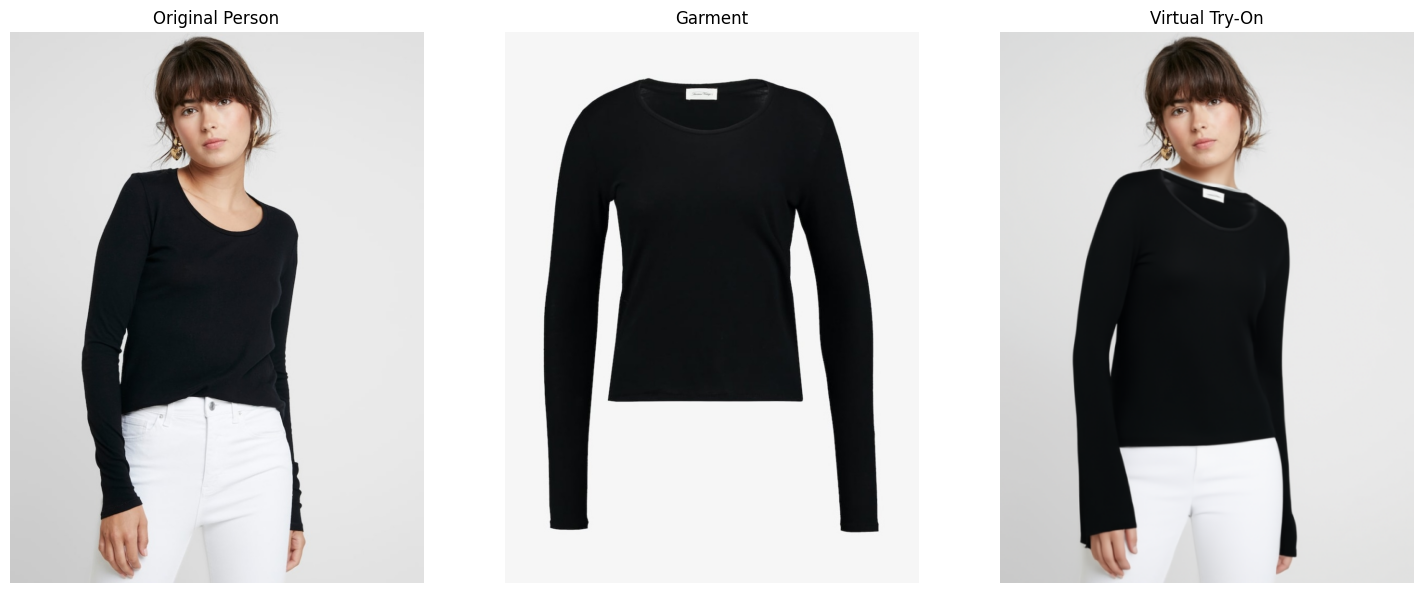

Saved: /content/fashn-vton-1.5/outputs/virtufit_first_test/virtufit_first_result.png


In [6]:
import os
from PIL import Image
import matplotlib.pyplot as plt

person_files = sorted(os.listdir(person_dir))

valid_pairs = [
    name for name in person_files
    if os.path.isfile(os.path.join(garment_dir, name))
    and name.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
]

assert valid_pairs, "No matching image pairs found!"

person_name = valid_pairs[0]

person_image = Image.open(
    os.path.join(person_dir, person_name)
).convert("RGB")

garment_image = Image.open(
    os.path.join(garment_dir, person_name)
).convert("RGB")

result = pipeline(
    person_image=person_image,
    garment_image=garment_image,
    category="tops",
    garment_photo_type="model",
    num_samples=1,
    num_timesteps=20,
    seed=42,
)

os.makedirs(output_dir, exist_ok=True)

result_path = os.path.join(output_dir, "virtufit_first_result.png")
result.images[0].save(result_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(person_image)
axes[0].set_title("Original Person")

axes[1].imshow(garment_image)
axes[1].set_title("Garment")

axes[2].imshow(result.images[0])
axes[2].set_title("Virtual Try-On")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Saved:", result_path)